In [3]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"kautsarhilmi99","key":"37f99caa3417eca448f2f35293688d6a"}'}

In [4]:
import os
os.makedirs('/root/.config/kaggle', exist_ok=True)
os.system('mv kaggle.json /root/.config/kaggle/')
os.system('chmod 600 /root/.config/kaggle/kaggle.json')
print("✅ Kaggle API siap!")

✅ Kaggle API siap!


In [5]:
!pip install kaggle -q

!kaggle competitions download -c playground-series-s6e8

import zipfile
with zipfile.ZipFile('playground-series-s6e8.zip', 'r') as z:
    z.extractall('.')

import os
print(os.listdir('.'))

100% 19.7M/19.7M [00:01<00:00, 17.3MB/s]

['.config', 'playground-series-s6e8.zip', 'sample_submission.csv', 'train.csv', 'test.csv', 'smartphone_addiction_prediction.py', 'sample_data']


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')
sub   = pd.read_csv('sample_submission.csv')

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print()
print(train.head())

Train shape: (691369, 14)
Test shape : (296302, 13)

   id   age  daily_screen_time_hours  social_media_hours  gaming_hours  \
0   0  24.0                      NaN                1.83          1.59   
1   1  19.0                     5.97                1.08           NaN   
2   2  18.0                     5.09                 NaN           NaN   
3   3  21.0                     6.42                1.26          1.42   
4   4  26.0                    11.20                1.87          2.81   

   work_study_hours  sleep_hours  notifications_per_day  app_opens_per_day  \
0              2.11         7.46                  122.0               38.0   
1              3.03         8.22                   76.0               19.0   
2               NaN         6.25                  134.0               60.0   
3              3.36         8.85                  112.0               94.0   
4              1.95         5.25                    NaN                NaN   

   weekend_screen_time  gender st

In [7]:
print("=== Missing Values ===")
missing = train.isnull().sum()
print(missing[missing > 0])

=== Missing Values ===
age                         28929
daily_screen_time_hours     95854
social_media_hours         133995
gaming_hours               126821
work_study_hours            51518
sleep_hours                 44480
notifications_per_day       67584
app_opens_per_day           80710
weekend_screen_time        112063
gender                      29034
stress_level                55148
academic_work_impact        44224
dtype: int64


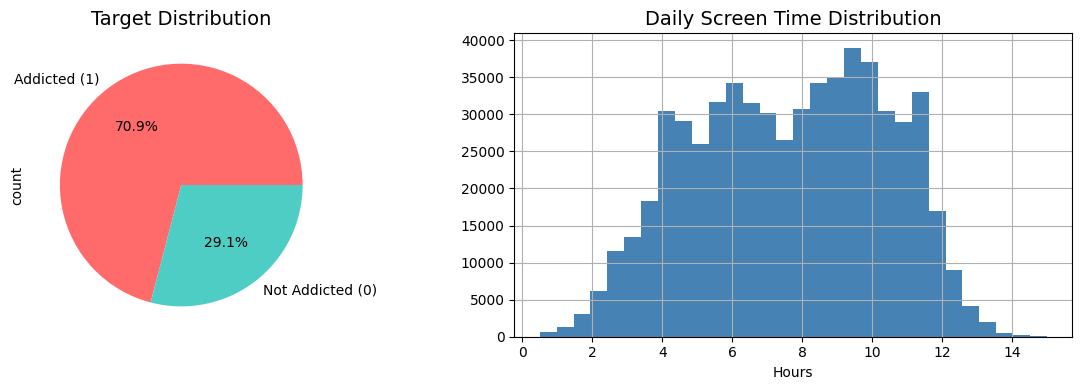

Plot saved!


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train['addicted_label'].value_counts().plot.pie(
    labels=['Addicted (1)', 'Not Addicted (0)'],
    autopct='%1.1f%%',
    colors=['#FF6B6B', '#4ECDC4'],
    ax=axes[0]
)
axes[0].set_title('Target Distribution', fontsize=14)

train['daily_screen_time_hours'].hist(bins=30, color='steelblue', ax=axes[1])
axes[1].set_title('Daily Screen Time Distribution', fontsize=14)
axes[1].set_xlabel('Hours')

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

In [9]:
def feature_engineering(df):
    df = df.copy()

    # Leisure vs productive
    df['leisure_screen_time']    = df['social_media_hours'].fillna(0) + df['gaming_hours'].fillna(0)
    df['productive_screen_time'] = df['work_study_hours'].fillna(0)
    df['leisure_to_productive']  = df['leisure_screen_time'] / (df['productive_screen_time'] + 1)

    # Weekend binge signal
    df['weekend_to_daily_ratio'] = df['weekend_screen_time'] / (df['daily_screen_time_hours'] + 1)

    # Sleep deprivation
    df['sleep_deficit']          = (7 - df['sleep_hours']).clip(lower=0)

    # Behavioral compulsion
    df['notif_per_app_open']     = df['notifications_per_day'] / (df['app_opens_per_day'] + 1)
    df['app_opens_log']          = np.log1p(df['app_opens_per_day'])

    # Screen vs sleep ratio
    df['screen_per_sleep']       = df['daily_screen_time_hours'] / (df['sleep_hours'] + 1)

    # Social media dominance
    df['social_media_ratio']     = df['social_media_hours'] / (df['daily_screen_time_hours'] + 1)

    return df

train = feature_engineering(train)
test  = feature_engineering(test)
print("Features after engineering:", train.shape[1])
print(train.head())

Features after engineering: 23
   id   age  daily_screen_time_hours  social_media_hours  gaming_hours  \
0   0  24.0                      NaN                1.83          1.59   
1   1  19.0                     5.97                1.08           NaN   
2   2  18.0                     5.09                 NaN           NaN   
3   3  21.0                     6.42                1.26          1.42   
4   4  26.0                    11.20                1.87          2.81   

   work_study_hours  sleep_hours  notifications_per_day  app_opens_per_day  \
0              2.11         7.46                  122.0               38.0   
1              3.03         8.22                   76.0               19.0   
2               NaN         6.25                  134.0               60.0   
3              3.36         8.85                  112.0               94.0   
4              1.95         5.25                    NaN                NaN   

   weekend_screen_time  ... addicted_label leisure_scre

In [10]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier
import warnings
warnings.filterwarnings('ignore')

# Encode kategorical
cat_cols = ['gender', 'stress_level', 'academic_work_impact']
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan)
enc.fit(pd.concat([train[cat_cols], test[cat_cols]], axis=0))
train[cat_cols] = enc.transform(train[cat_cols])
test[cat_cols]  = enc.transform(test[cat_cols])

FEATURES = [
    'age', 'daily_screen_time_hours', 'social_media_hours',
    'gaming_hours', 'work_study_hours', 'sleep_hours',
    'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time',
    'gender', 'stress_level', 'academic_work_impact',
    'leisure_screen_time', 'productive_screen_time', 'leisure_to_productive',
    'weekend_to_daily_ratio', 'sleep_deficit', 'notif_per_app_open',
    'app_opens_log', 'screen_per_sleep', 'social_media_ratio',
]

X      = train[FEATURES]
y      = train['addicted_label']
X_test = test[FEATURES]

In [11]:
np.random.seed(42)
sample_idx = np.random.choice(len(train), 150000, replace=False)
X_s, y_s = X.iloc[sample_idx], y.iloc[sample_idx]

params = dict(
    max_iter=500,
    learning_rate=0.08,
    max_leaf_nodes=63,
    min_samples_leaf=80,
    l2_regularization=1.0,
    max_bins=255,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42,
    verbose=0,
    class_weight='balanced',
)

N_SPLITS  = 3
skf       = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
oof_preds = np.zeros(len(X_s))
models    = []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_s, y_s), 1):
    m = HistGradientBoostingClassifier(**params)
    m.fit(X_s.iloc[tr_idx], y_s.iloc[tr_idx])
    oof_preds[val_idx] = m.predict_proba(X_s.iloc[val_idx])[:, 1]
    models.append(m)
    fold_auc = roc_auc_score(y_s.iloc[val_idx], oof_preds[val_idx])
    print(f"Fold {fold} | AUC: {fold_auc:.5f} | Iters: {m.n_iter_}")

oof_auc = roc_auc_score(y_s, oof_preds)
print(f"\n>>> Overall CV AUC: {oof_auc:.5f} <<<")

Fold 1 | AUC: 0.95588 | Iters: 315
Fold 2 | AUC: 0.95698 | Iters: 269
Fold 3 | AUC: 0.95545 | Iters: 311

>>> Overall CV AUC: 0.95608 <<<


In [12]:
test_preds = np.mean([m.predict_proba(X_test)[:, 1] for m in models], axis=0)

sub['addicted_label'] = test_preds
sub.to_csv('submission.csv', index=False)

print("Submission preview:")
print(sub.head(10))
print(f"\nPred mean : {test_preds.mean():.4f}")
print(f"Train mean: {y.mean():.4f}")

Submission preview:
       id  addicted_label
0  691369        0.995935
1  691370        0.918057
2  691371        0.902540
3  691372        0.968922
4  691373        0.995049
5  691374        0.761327
6  691375        0.746807
7  691376        0.271990
8  691377        0.968581
9  691378        0.161437

Pred mean : 0.6538
Train mean: 0.7094


In [13]:
from google.colab import files
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
!kaggle competitions submit -c playground-series-s6e8 \
    -f submission.csv \
    -m "HistGBM 3-fold CV | AUC 0.9561 | Feature Engineering"

100% 7.42M/7.42M [00:01<00:00, 5.81MB/s]
Successfully submitted to Predicting Smartphone Addiction

In [15]:
notebook_code = '''
# isi kode lengkap dari tadi
'''
with open('smartphone_addiction_prediction.py', 'w') as f:
    f.write(notebook_code)
files.download('smartphone_addiction_prediction.py')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>